# Exercise 8: Feature Engineering (Solution)
### (010000) Machine Learning - Spring 2026
### Prof. Cheol Jeong, Sejong University

# 1) Load data

In [ ]:
import pandas as pd
import numpy as np

# Read the CSV file uploaded to the current Colab working directory
df = pd.read_csv("Housing price dataset_modified.csv")

# Show the size of the dataset and the first 5 rows
print(df.shape)
print("Columns:", list(df.columns))
df.head()


(506, 12)
Columns: ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'MEDV']


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,36.2


# 2) Select input and target

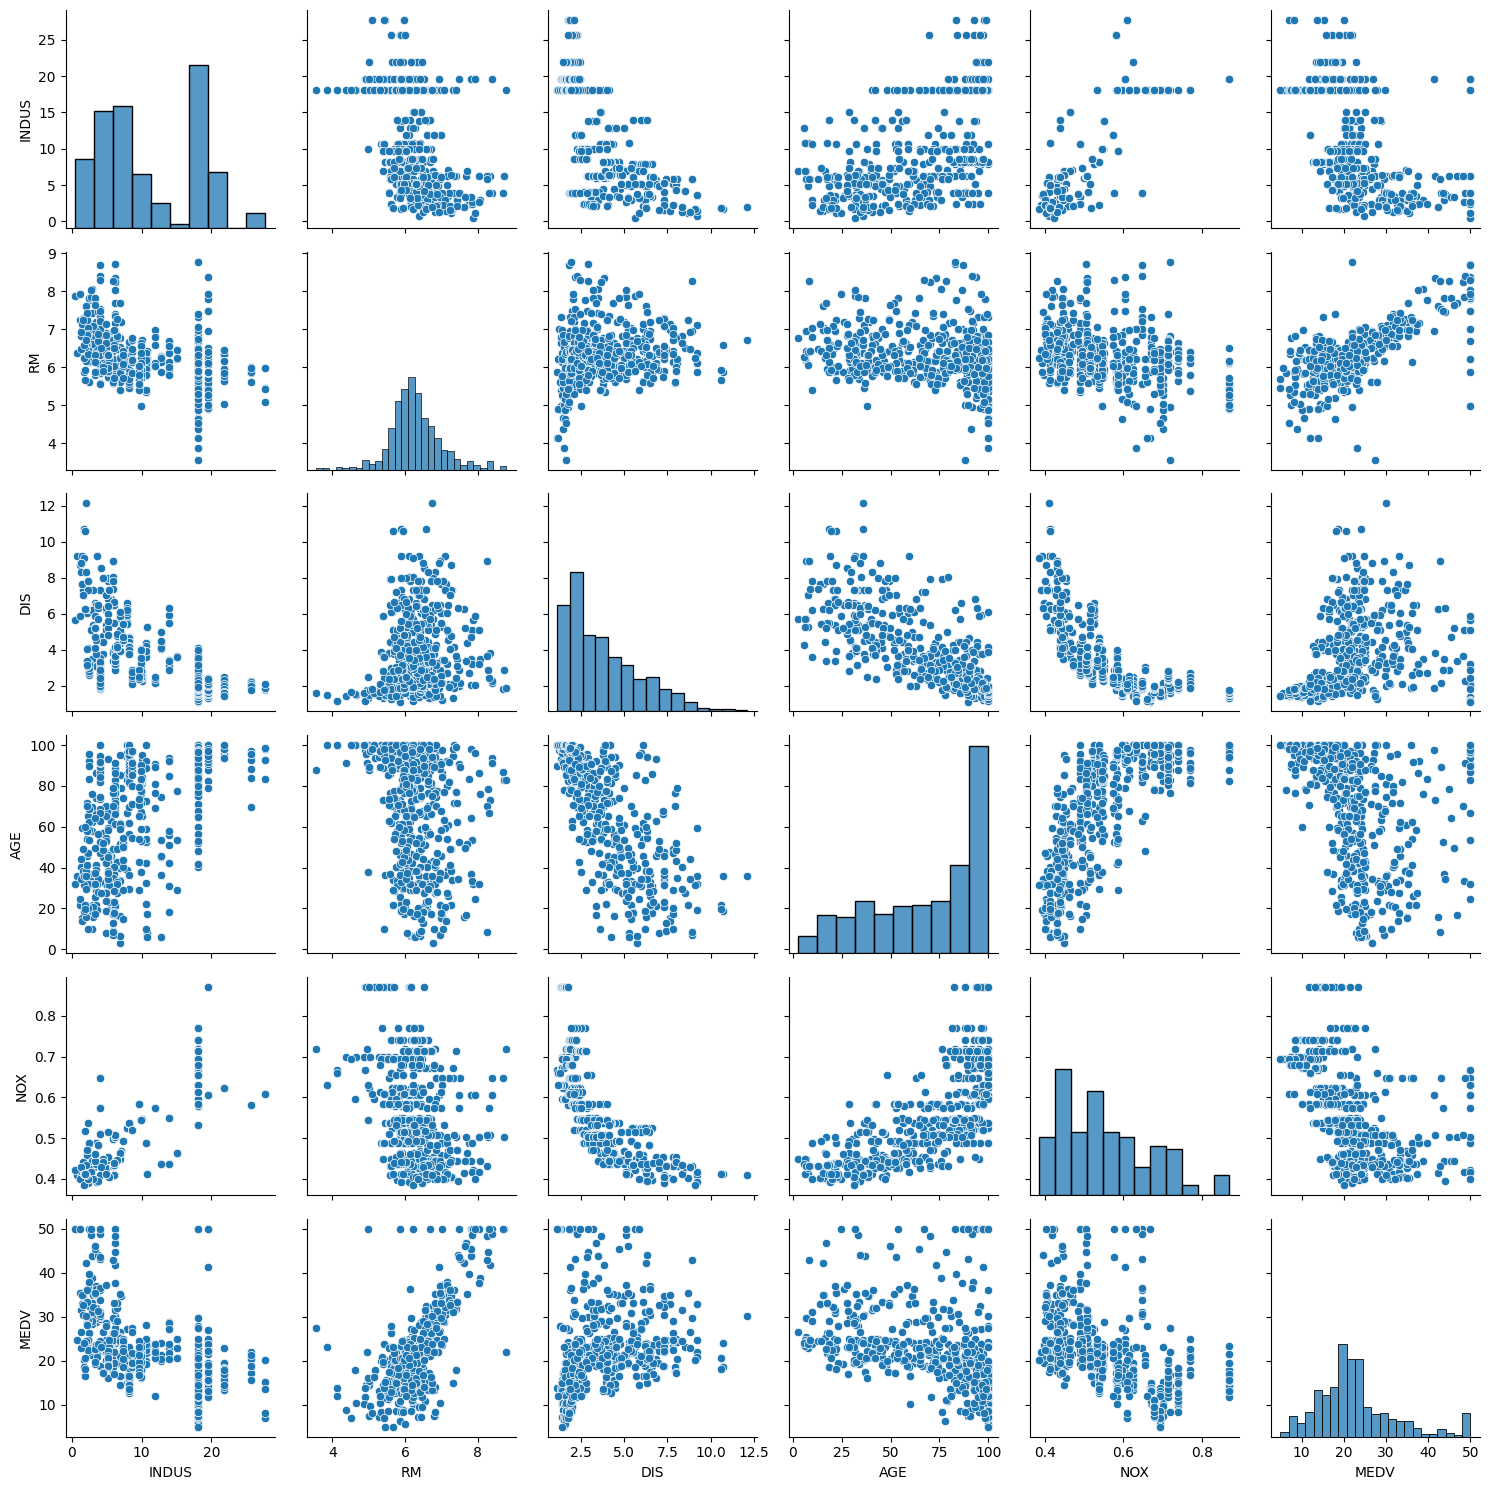

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
cols = ["INDUS", "RM", "DIS", "AGE", "NOX", "MEDV"]

sns.pairplot(data=df, x_vars=cols, y_vars=cols)

plt.tight_layout()
plt.show()

# 2) Select input and target, then make train, validation, and test sets

In [ ]:
from sklearn.model_selection import train_test_split

target_col = "MEDV"

selected_features = ["INDUS", "RM", "DIS", "AGE", "NOX"]

# Use the selected input features and MEDV as the target
X = df[selected_features].copy()
y = df[target_col].copy()

# Split the dataset into train / validation / test sets
# 60% train, 20% validation, 20% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=26
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=26
)

print("Selected features:", selected_features)
print("X_train shape:", X_train.shape)
print("X_val shape  :", X_val.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_val shape  :", y_val.shape)
print("y_test shape :", y_test.shape)


Selected features: ['INDUS', 'RM', 'DIS', 'AGE', 'NOX']
X_train shape: (303, 5)
X_val shape  : (101, 5)
X_test shape : (102, 5)
y_train shape: (303,)
y_val shape  : (101,)
y_test shape : (102,)


# 3) Train a linear regression model using the original features

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Baseline model: use only the original selected features
reg_original = LinearRegression()
reg_original.fit(X_train, y_train)

y_train_pred_original = reg_original.predict(X_train)
y_val_pred_original = reg_original.predict(X_val)

train_mse_original = mean_squared_error(y_train, y_train_pred_original)
val_mse_original = mean_squared_error(y_val, y_val_pred_original)

print("Original-feature model")
print("Training MSE  :", train_mse_original)
print("Validation MSE:", val_mse_original)


Original-feature model
Training MSE  : 37.924691520843204
Validation MSE: 32.39517426895434


# 4) Transform features for selected columns

In [ ]:
# Original features
X_train_orig = X_train[["INDUS", "RM", "DIS", "AGE", "NOX"]].copy()
X_val_orig = X_val[["INDUS", "RM", "DIS", "AGE", "NOX"]].copy()
X_test_orig = X_test[["INDUS", "RM", "DIS", "AGE", "NOX"]].copy()

X_train_eng = X_train[["INDUS", "RM", "AGE", "DIS", "NOX"]].copy()
X_val_eng = X_val[["INDUS", "RM", "AGE", "DIS", "NOX"]].copy()
X_test_eng = X_test[["INDUS", "RM", "AGE", "DIS", "NOX"]].copy()

X_train_eng["RM_NOX"] = X_train["RM"] * X_train["NOX"]
X_val_eng["RM_NOX"] = X_val["RM"] * X_val["NOX"]
X_test_eng["RM_NOX"] = X_test["RM"] * X_test["NOX"]

# Reorder columns
X_train_eng = X_train_eng[["INDUS", "RM", "RM_NOX", "DIS", "NOX"]]
X_val_eng = X_val_eng[["INDUS", "RM", "RM_NOX", "DIS", "NOX"]]
X_test_eng = X_test_eng[["INDUS", "RM", "RM_NOX", "DIS", "NOX"]]

# 5) Train a linear regression model using the transformed (engineered) features

In [ ]:
reg_engineered = LinearRegression()
reg_engineered.fit(X_train_eng, y_train)

y_train_pred_eng = reg_engineered.predict(X_train_eng)
y_val_pred_eng = reg_engineered.predict(X_val_eng)

train_mse_eng = mean_squared_error(y_train, y_train_pred_eng)
val_mse_eng = mean_squared_error(y_val, y_val_pred_eng)

print("Transformed-feature model")
print("Training MSE  :", train_mse_eng)
print("Validation MSE:", val_mse_eng)


Transformed-feature model
Training MSE  : 35.50735183635503
Validation MSE: 24.518650122582528


# 6) Compare the training and validation MSE of the original features and the transformed features

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display

comparison_df = pd.DataFrame([
    {
        "Model": "Original features",
        "Number of features": X_train.shape[1],
        "Training MSE": train_mse_original,
        "Validation MSE": val_mse_original,
    },
    {
        "Model": "Transformed features",
        "Number of features": X_train_eng.shape[1],
        "Training MSE": train_mse_eng,
        "Validation MSE": val_mse_eng,
    }
])

print(comparison_df)
display(comparison_df)

                  Model  Number of features  Training MSE  Validation MSE
0     Original features                   5     37.924692       32.395174
1  Transformed features                   5     35.507352       24.518650


,Model,Number of features,Training MSE,Validation MSE
0,Original features,5,37.924692,32.395174
1,Transformed features,5,35.507352,24.518650
